In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

In [4]:
maze=np.zeros((5,5),dtype=int)
walls=[(1,1),(1,2),(3,2),(3,3)]
for r,c in walls:
    maze[r,c]=1
start=(0,0)
goal=(4,4)
print(maze)
    

[[0 0 0 0 0]
 [0 1 1 0 0]
 [0 0 0 0 0]
 [0 0 1 1 0]
 [0 0 0 0 0]]


In [18]:

actions = [0, 1, 2, 3]  # Up, Down, Left, Right

alpha = 0.1
gamma = 0.9
epsilon = 1.0
episodes = 5000

q_table = np.zeros((25, 4))

def state_to_index(state):
    return state[0] * 5 + state[1]

def step(state, action):
    r, c = state

    if action == 0:       # Up
        r -= 1
    elif action == 1:     # Down
        r += 1
    elif action == 2:     # Left
        c -= 1
    elif action == 3:     # Right
        c += 1

    # Check boundaries and walls
    if (r < 0 or r >= 5 or c < 0 or c >= 5
            or maze[r, c] == 1):
        return state, -5, False

    next_state = (r, c)

    # Goal reached
    if next_state == goal:
        return next_state, 100, True

    return next_state, -1, False


In [19]:
for episode in range(episodes):
    state=start
    for _ in range(100):
        s=state_to_index(state)
        if random.random()<epsilon:
           action=random.choice(actions)
        else:
            action=int(np.argmax(q_table[s]))
        next_state,reward,done=step(state,action)
        ns=state_to_index(next_state)
        if done:
            target=reward
        else:
            target=reward+gamma*np.max(q_table[ns])
        q_table[s,action]+=alpha*(target-q_table[s,action])
        state=next_state
        if done:
            break
    epsilon=max(0.01,epsilon*0.995)
print("Training completed!")
    
    
    

Training completed!


In [20]:
# Extract the learned path
state = start
path = [state]
visited = {state}

for _ in range(25):
    s = state_to_index(state)

    # Find valid moves that do not revisit old cells
    valid_actions = []

    for action in actions:
        next_state, reward, done = step(state, action)

        if next_state != state and (
            next_state not in visited or done
        ):
            valid_actions.append((action, next_state, done))

    if not valid_actions:
        break

    # Choose the best Q-value among the available moves
    action, next_state, done = max(
        valid_actions,
        key=lambda item: q_table[s, item[0]]
    )

    state = next_state
    path.append(state)
    visited.add(state)

    if done:
        break

print("Learned path:", path)
print("Reached goal:", state == goal)

Learned path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
Reached goal: True


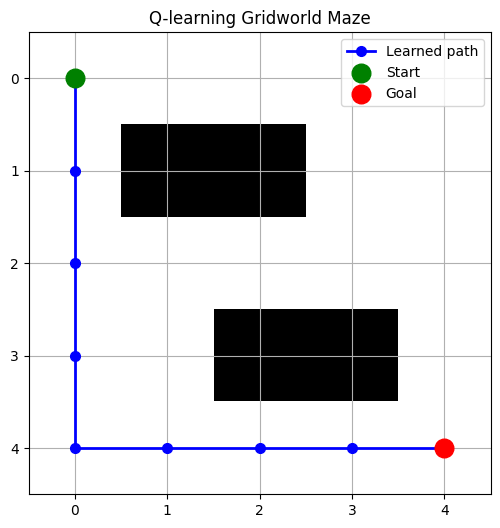

In [21]:
# Create a copy of the maze for visualization
display_maze = maze.copy().astype(float)

plt.figure(figsize=(6, 6))

# Display the maze
plt.imshow(display_maze, cmap="binary", vmin=0, vmax=1)

# Extract row and column coordinates from the path
path_rows = [p[0] for p in path]
path_cols = [p[1] for p in path]

# Draw the learned path
plt.plot(
    path_cols, path_rows, "bo-",
    linewidth=2, markersize=7, label="Learned path"
)

# Mark the start and goal
plt.scatter(
    start[1], start[0], color="green",
    s=180, label="Start", zorder=3
)

plt.scatter(
    goal[1], goal[0], color="red",
    s=180, label="Goal", zorder=3
)

plt.xticks(range(5))
plt.yticks(range(5))
plt.grid(True)
plt.title("Q-learning Gridworld Maze")
plt.legend()
plt.show()